<a href="https://colab.research.google.com/github/trisadhiyanasywa-svg/Praktikum_MachineLearning/blob/TI08_Trisa_0110225049/Praktikum6_Mandiri_ML_Trisa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Mandiri

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [3]:
df = pd.read_csv('/content/drive/MyDrive/ML 2026/PraktikumMandiri06/data/student_academic_performance.csv')

# Melihat beberapa baris awal dataset
df.head()

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


In [4]:
# Melihat informasi tipe data dan nilai yang hilang (missing values)
df.info()

# Melihat nama-nama kolom
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   gender                    480 non-null    object
 1   NationalITy               480 non-null    object
 2   PlaceofBirth              480 non-null    object
 3   StageID                   480 non-null    object
 4   GradeID                   480 non-null    object
 5   SectionID                 480 non-null    object
 6   Topic                     480 non-null    object
 7   Semester                  480 non-null    object
 8   Relation                  480 non-null    object
 9   raisedhands               480 non-null    int64 
 10  VisITedResources          480 non-null    int64 
 11  AnnouncementsView         480 non-null    int64 
 12  Discussion                480 non-null    int64 
 13  ParentAnsweringSurvey     480 non-null    object
 14  ParentschoolSatisfaction  

In [5]:
print(df.columns)

Index(['gender', 'NationalITy', 'PlaceofBirth', 'StageID', 'GradeID',
       'SectionID', 'Topic', 'Semester', 'Relation', 'raisedhands',
       'VisITedResources', 'AnnouncementsView', 'Discussion',
       'ParentAnsweringSurvey', 'ParentschoolSatisfaction',
       'StudentAbsenceDays', 'Class'],
      dtype='object')


Jumlah fitur setelah encoding: 72
Model Decision Tree berhasil dilatih!

Akurasi: 84.38%

Laporan Klasifikasi:
              precision    recall  f1-score   support

           H       0.73      0.86      0.79        22
           L       0.88      0.88      0.88        26
           M       0.89      0.81      0.85        48

    accuracy                           0.84        96
   macro avg       0.83      0.85      0.84        96
weighted avg       0.85      0.84      0.84        96



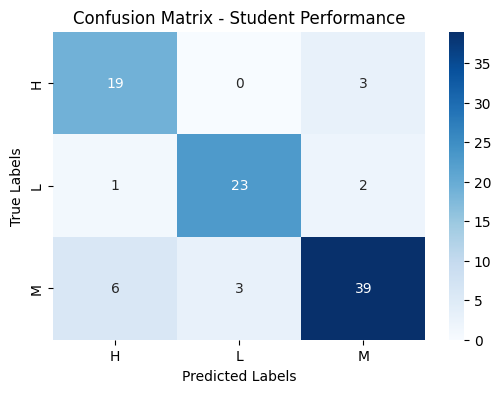

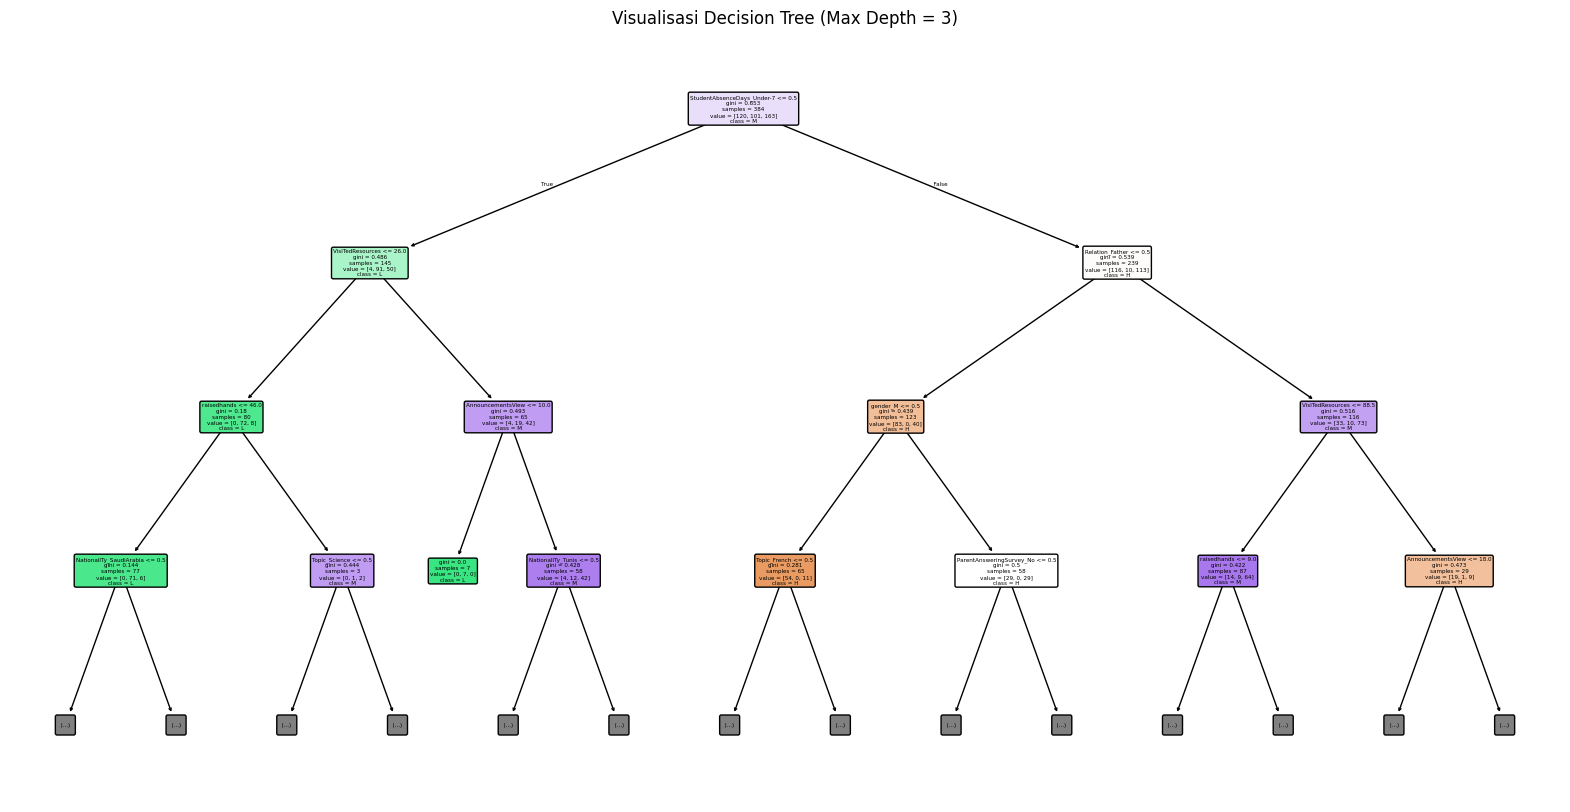

In [6]:
# 1. Menentukan Fitur (X) dan Target (y)
# Fitur (X) menggunakan seluruh kolom kecuali kolom 'Class'
X = df.drop(columns=['Class'])
# Target (y) adalah kolom 'Class' yang ingin kita prediksi
y = df['Class']

# 2. Mengubah data kategorikal (teks) menjadi numerik menggunakan One-Hot Encoding
# Karena Decision Tree scikit-learn memerlukan input berupa angka
X = pd.get_dummies(X)

print(f"Jumlah fitur setelah encoding: {X.shape[1]}")

# 3. Membagi data menjadi data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Membuat dan Melatih Model Decision Tree
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)
print("Model Decision Tree berhasil dilatih!\n")

# 5. Evaluasi Model
y_pred = model.predict(X_test)

# Menghitung Akurasi
print(f"Akurasi: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

# Laporan Klasifikasi
print("Laporan Klasifikasi:")
print(classification_report(y_test, y_pred))

# Visualisasi Confusion Matrix dengan Seaborn
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title("Confusion Matrix - Student Performance")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

# 6. Visualisasi Pohon Keputusan (Decision Tree Plot)
# max_depth dibatasi 3 agar gambarnya tidak terlalu besar dan mudah dibaca
plt.figure(figsize=(20, 10))
plot_tree(model,
          feature_names=X.columns,
          class_names=[str(c) for c in model.classes_],
          filled=True,
          rounded=True,
          max_depth=3)
plt.title("Visualisasi Decision Tree (Max Depth = 3)")
plt.show()

Data train: 384 | Data test: 96
Akurasi training: 0.849
Support vector per kelas: [ 73  41 107]

Akurasi: 79.17%

              precision    recall  f1-score   support

           H       0.80      0.73      0.76        22
           L       0.79      0.85      0.81        26
           M       0.79      0.79      0.79        48

    accuracy                           0.79        96
   macro avg       0.79      0.79      0.79        96
weighted avg       0.79      0.79      0.79        96



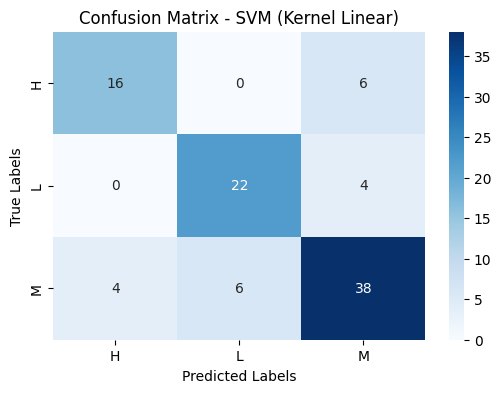

In [7]:
# ===== SVM (model utama) =====
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Target diubah ke angka (H=0, L=1, M=2); X sudah hasil one-hot encoding
le = LabelEncoder()
y_enc = le.fit_transform(df['Class'])

# Split yang sama dengan Decision Tree (80:20, random_state=42)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=42)
print("Data train:", Xs_train.shape[0], "| Data test:", Xs_test.shape[0])

# Model SVM kernel linear
svm_model = SVC(kernel='linear')
svm_model.fit(Xs_train, ys_train)
print("Akurasi training:", round(svm_model.score(Xs_train, ys_train), 4))   # ±0.849
print("Support vector per kelas:", svm_model.n_support_)                   # [73 41 107]

# Evaluasi
svm_pred = svm_model.predict(Xs_test)
print(f"\nAkurasi: {accuracy_score(ys_test, svm_pred) * 100:.2f}%\n")      # 79.17%
print(classification_report(ys_test, svm_pred, target_names=le.classes_))

cm = confusion_matrix(ys_test, svm_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - SVM (Kernel Linear)")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah data train: {X_train.shape[0]}")
print(f"Jumlah data test: {X_test.shape[0]}")

Jumlah data train: 384
Jumlah data test: 96


In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(Xs_train)
hasil = []
for k in ['linear', 'poly', 'rbf']:
    a = SVC(kernel=k).fit(Xs_train, ys_train).score(Xs_test, ys_test) * 100
    b = SVC(kernel=k).fit(scaler.transform(Xs_train), ys_train).score(scaler.transform(Xs_test), ys_test) * 100
    hasil.append([k, round(a, 2), round(b, 2)])
print(pd.DataFrame(hasil, columns=['Kernel', 'Tanpa scaling', 'Dengan scaling']))

   Kernel  Tanpa scaling  Dengan scaling
0  linear          79.17           77.08
1    poly          64.58           71.88
2     rbf          64.58           71.88


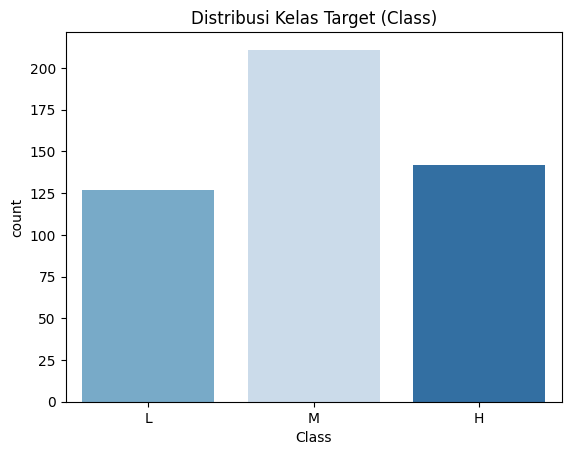

In [10]:
sns.countplot(x='Class', data=df, order=['L', 'M', 'H'], hue='Class', palette='Blues', legend=False)
plt.title('Distribusi Kelas Target (Class)')
plt.show()

[0.64251187 0.18870684]


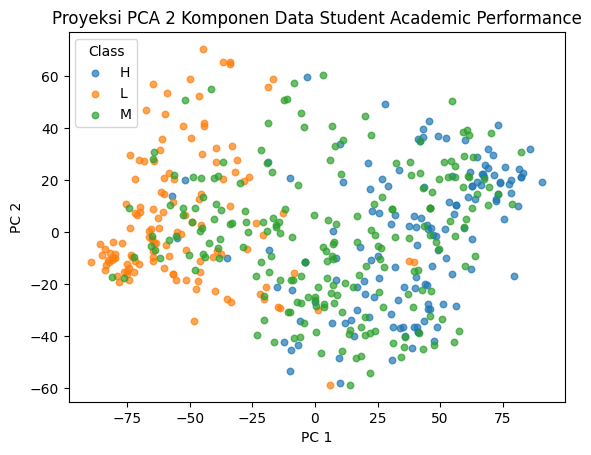

In [11]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
Z = pca.fit_transform(X)
print(pca.explained_variance_ratio_)   # ±[0.6425 0.1887]
for i, c in enumerate(le.classes_):
    plt.scatter(Z[y_enc == i, 0], Z[y_enc == i, 1], label=c, alpha=0.7, s=22)
plt.xlabel('PC 1'); plt.ylabel('PC 2'); plt.legend(title='Class')
plt.title('Proyeksi PCA 2 Komponen Data Student Academic Performance')
plt.show()

In [12]:
# Membuat model Decision Tree
model = DecisionTreeClassifier(random_state=42)

# Melatih model
model.fit(X_train, y_train)
print("Model Decision Tree berhasil dilatih!")

Model Decision Tree berhasil dilatih!


Akurasi: 84.38%

Laporan Klasifikasi:
              precision    recall  f1-score   support

           H       0.73      0.86      0.79        22
           L       0.88      0.88      0.88        26
           M       0.89      0.81      0.85        48

    accuracy                           0.84        96
   macro avg       0.83      0.85      0.84        96
weighted avg       0.85      0.84      0.84        96



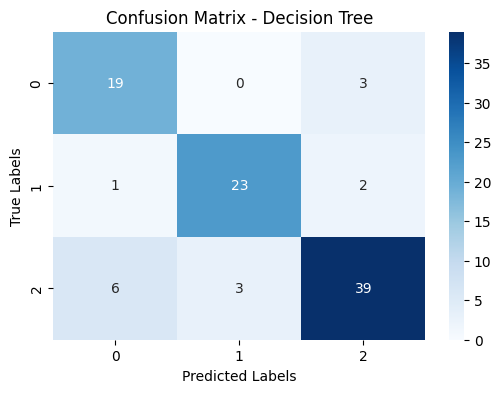

In [13]:
import seaborn as sns

# Melakukan prediksi
y_pred = model.predict(X_test)

# Menghitung Akurasi
print(f"Akurasi: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

# Laporan Klasifikasi
print("Laporan Klasifikasi:")
print(classification_report(y_test, y_pred))

# Membuat Confusion Matrix Visualisasi dengan Seaborn
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

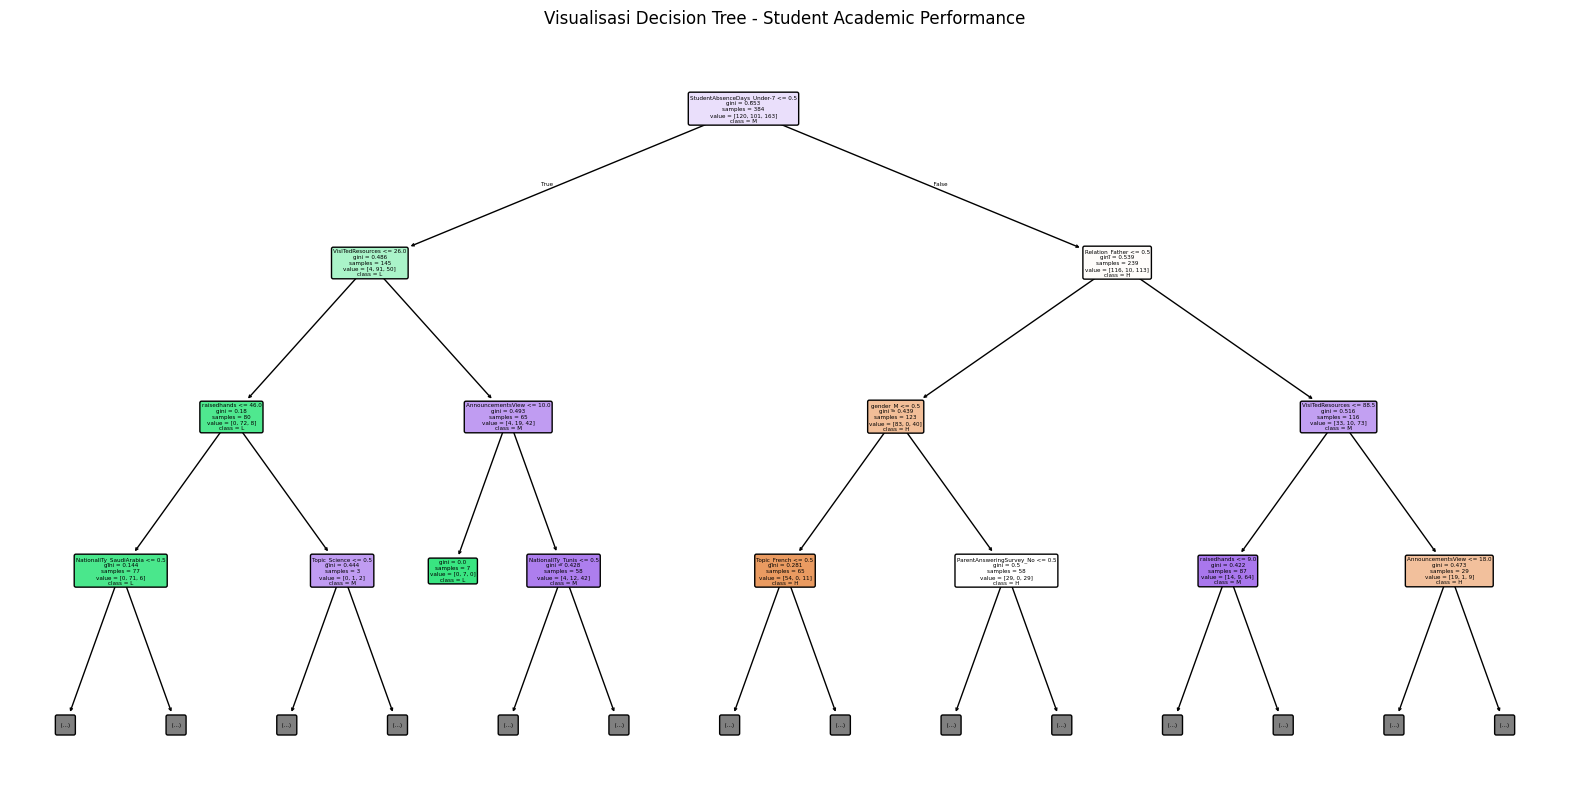

In [14]:
plt.figure(figsize=(20, 10))
plot_tree(model,
          feature_names=X.columns,
          class_names=[str(cls) for cls in model.classes_],
          filled=True,
          rounded=True,
          max_depth=3) # <-- Batasi kedalaman agar mudah dibaca
plt.title("Visualisasi Decision Tree - Student Academic Performance")
plt.show()